# Differential Privacy for Neural Networks

## Project: The Impact of Overfitting on Privacy Risks in Neural Networks

### Objective
Train a neural network using Differentially Private Stochastic Gradient Descent (DP-SGD) and evaluate the trade-off between model utility and privacy.

### Experimental Plan
1. Reuse the Fashion-MNIST dataset and the **saved** data split from `01_baseline_model` (`split_indices.json`).
2. Train the model using DP-SGD with Opacus for several privacy budgets (epsilon) and several training seeds.
3. Measure the privacy budget (epsilon) of every run.
4. Evaluate training, validation and test performance.
5. Run exactly the same loss-based Membership Inference Attack (MIA) as in notebook 1 (members = training subset, non-members = official test set).
6. Compare the differentially private models with the baseline models (epsilon = infinity) and relate the generalization gap to attack performance.

### Reproducibility
- Dataset: Fashion-MNIST
- Model: BaselineMLP
- Data split, number of epochs, batch size, learning rate and training seeds are read from the files saved by notebook 1.
- Run notebook 1 completely before this notebook.

In [1]:
import random
import json
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

import opacus
from opacus import PrivacyEngine

from IPython.display import display, Markdown
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import roc_auc_score, roc_curve

import warnings

warnings.filterwarnings(
    "ignore",
    message="Secure RNG turned off.*",
    category=UserWarning
)

warnings.filterwarnings(
    "ignore",
    message="Using a non-full backward hook.*",
    category=UserWarning
)
SEED = 42


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
METRICS_DIR = RESULTS_DIR / "metrics"
CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"

for directory in [DATA_DIR, FIGURES_DIR, METRICS_DIR, CHECKPOINT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Imports completed successfully.")
print("Project directory:", PROJECT_DIR)
print("Python version:", platform.python_version())
print("PyTorch version:", torch.__version__)
print("Opacus version:", opacus.__version__)
print("Device:", DEVICE)
print("Random seed:", SEED)

Imports completed successfully.
Project directory: C:\Users\HADIS\Documents\overfitting-privacy-neural-networks
Python version: 3.11.15
PyTorch version: 2.2.2+cpu
Opacus version: 1.4.1
Device: cpu
Random seed: 42


In [2]:
with open(METRICS_DIR / "baseline_config.json", "r", encoding="utf-8") as file:
    baseline_config = json.load(file)

BATCH_SIZE = baseline_config["batch_size"]
EPOCHS = baseline_config["epochs"]
LEARNING_RATE = baseline_config["learning_rate"]
TRAIN_SEEDS = baseline_config["train_seeds"]

assert baseline_config["mia_nonmember_source"] == "test"

TARGET_DELTA = 1e-5
MAX_GRAD_NORM = 1.0
EPSILON_SWEEP = [1.0, 2.0, 4.0, 8.0]   
MAIN_EPSILON = 8.0                      
DP_SEEDS = TRAIN_SEEDS               

print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Training seeds:", TRAIN_SEEDS)
print("Delta:", TARGET_DELTA)
print("Max grad norm:", MAX_GRAD_NORM)
print("Epsilon sweep:", EPSILON_SWEEP)

Batch size: 128
Epochs: 30
Learning rate: 0.001
Training seeds: [42, 43, 44]
Delta: 1e-05
Max grad norm: 1.0
Epsilon sweep: [1.0, 2.0, 4.0, 8.0]


In [3]:
transform = transforms.ToTensor()

full_train_dataset = datasets.FashionMNIST(
    root=str(DATA_DIR),
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root=str(DATA_DIR),
    train=False,
    download=True,
    transform=transform
)


with open(METRICS_DIR / "split_indices.json", "r", encoding="utf-8") as file:
    split = json.load(file)

train_dataset = Subset(full_train_dataset, split["train_indices"])
validation_dataset = Subset(full_train_dataset, split["validation_indices"])

assert set(split["train_indices"]).isdisjoint(split["validation_indices"])
assert len(train_dataset) == baseline_config["train_size"]
assert len(validation_dataset) == baseline_config["validation_size"]
assert len(test_dataset) == baseline_config["test_size"]

print("Training samples:", len(train_dataset))
print("Validation samples:", len(validation_dataset))
print("Test samples:", len(test_dataset))
print("Number of classes:", len(full_train_dataset.classes))
print("Class names:", full_train_dataset.classes)

Training samples: 50000
Validation samples: 10000
Test samples: 10000
Number of classes: 10
Class names: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [4]:
class BaselineMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


architecture_summary = BaselineMLP()

print(architecture_summary)
print(
    "Trainable parameters:",
    sum(p.numel() for p in architecture_summary.parameters() if p.requires_grad)
)

BaselineMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 235146


In [5]:
train_eval_loader = DataLoader(train_dataset, batch_size=1024, shuffle=False, num_workers=0)
validation_loader = DataLoader(validation_dataset, batch_size=1024, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=1024, shuffle=False, num_workers=0)


@torch.no_grad()
def evaluate(model, loader, device=DEVICE):
    """Average cross-entropy loss and accuracy in evaluation mode."""
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss_sum += nn.functional.cross_entropy(logits, labels, reduction="sum").item()
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return loss_sum / total, correct / total


print("Evaluation loaders are ready.")

Evaluation loaders are ready.


## Membership Inference Attack (MIA)

A loss-based Membership Inference Attack is used to investigate whether an attacker can distinguish training samples (members) from unseen samples (non-members) based on the model's prediction losses.

- Members: the training subset (50,000). Non-members: the official test set (10,000). This is **identical** to notebook 1, for the baseline and for every DP model.
- Score: `logit(true class) - logsumexp(other logits)` in float64, a monotone transform of the cross-entropy loss that does not saturate at 0 (float32 cross-entropy produces many exact zeros and ties, which forces TPR@1%FPR = 0).
- Metrics: ROC-AUC with a bootstrap 95% confidence interval, TPR at FPR <= 1% and <= 0.1%, and the attack advantage `max(TPR - FPR)`.

The helper functions below are copied unchanged from notebook 1 so that exactly the same attack procedure and evaluation protocol is used for both models.

In [6]:
@torch.no_grad()
def collect_membership_scores(model, loader, device=DEVICE):
    model.eval()
    chunks = []
    for images, labels in loader:
        logits = model(images.to(device)).double()
        labels = labels.to(device)
        true_logit = logits.gather(1, labels[:, None]).squeeze(1)
        other_logits = logits.scatter(1, labels[:, None], float("-inf"))
        chunks.append((true_logit - torch.logsumexp(other_logits, dim=1)).cpu())
    return torch.cat(chunks).numpy()


def scores_to_loss(scores):
    return np.logaddexp(0.0, -scores)


def mia_metrics(member_scores, nonmember_scores, n_boot=200, seed=SEED):
    y_true = np.concatenate([np.ones(len(member_scores)), np.zeros(len(nonmember_scores))])
    y_score = np.concatenate([member_scores, nonmember_scores])

    auc = roc_auc_score(y_true, y_score)
    fpr, tpr, _ = roc_curve(y_true, y_score, drop_intermediate=False)

    def tpr_at(max_fpr):
        return float(tpr[fpr <= max_fpr].max())

    rng = np.random.default_rng(seed)
    boot_aucs = []
    for _ in range(n_boot):
        m = rng.choice(member_scores, size=len(member_scores), replace=True)
        n = rng.choice(nonmember_scores, size=len(nonmember_scores), replace=True)
        boot_aucs.append(
            roc_auc_score(
                np.concatenate([np.ones(len(m)), np.zeros(len(n))]),
                np.concatenate([m, n]),
            )
        )
    ci_low, ci_high = np.percentile(boot_aucs, [2.5, 97.5])

    return {
        "roc_auc": float(auc),
        "auc_ci_low": float(ci_low),
        "auc_ci_high": float(ci_high),
        "tpr_at_fpr_1pct": tpr_at(0.01),
        "tpr_at_fpr_0_1pct": tpr_at(0.001),
        "attack_advantage": float(np.max(tpr - fpr)),
        "tie_fraction": float(1.0 - len(np.unique(y_score)) / len(y_score)),
    }

## DP-SGD Training

We train the same `BaselineMLP` with DP-SGD (Opacus): per-sample gradient clipping with `max_grad_norm` and Gaussian noise whose multiplier is calibrated so that the target epsilon is reached after the planned number of epochs (RDP accountant, Poisson sampling).

For every run we record:

- training and validation metrics, computed at the end of each epoch in evaluation mode (same procedure as the baseline);
- epsilon after each epoch;
- the epsilon computed again with a much wider range of RDP orders (alphas). Opacus warns when the optimal order is the largest alpha of its default grid; in that case the default epsilon may be loose, and the second value shows whether a wider grid changes the bound.

After training, the weights are copied into a plain `BaselineMLP` (`model._module`) so that the saved state dict has no wrapper-prefix and can be loaded directly.

The learning rate and the clipping norm are **not tuned** for DP. Part of the utility loss can therefore come from untuned hyperparameters rather than from DP itself.

Runtime: `len(EPSILON_SWEEP) * len(DP_SEEDS)` DP runs of 30 epochs each. Reduce `DP_SEEDS` if this takes too long.

In [7]:
RDP_ALPHAS = [1 + x / 10.0 for x in range(1, 100)] + list(range(12, 256))

def train_dp(target_epsilon, train_seed):
    set_seed(train_seed)

    model = BaselineMLP().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(train_seed)
    )

    privacy_engine = PrivacyEngine(accountant="rdp")

    with warnings.catch_warnings():
        warnings.simplefilter("ignore") 
        model, optimizer, train_loader = privacy_engine.make_private_with_epsilon(
            module=model,
            optimizer=optimizer,
            data_loader=train_loader,
            epochs=EPOCHS,
            target_epsilon=target_epsilon,
            target_delta=TARGET_DELTA,
            max_grad_norm=MAX_GRAD_NORM
        )

    rows = []

    for epoch in range(1, EPOCHS + 1):
        model.train()

        for images, labels in train_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)

            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()

        train_loss, train_accuracy = evaluate(model, train_eval_loader)
        val_loss, val_accuracy = evaluate(model, validation_loader)

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            epsilon = privacy_engine.get_epsilon(TARGET_DELTA)

        rows.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "accuracy_gap": train_accuracy - val_accuracy,
            "loss_gap": val_loss - train_loss,
            "epsilon": epsilon,
        })

        print(
            f"[eps {target_epsilon:g} | seed {train_seed}] Epoch {epoch:02d}/{EPOCHS} | "
            f"Train Acc: {train_accuracy:.4f} | Val Acc: {val_accuracy:.4f} | "
            f"Val Loss: {val_loss:.4f} | Epsilon: {epsilon:.4f}"
        )

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            epsilon_wide_alphas = float(
                privacy_engine.accountant.get_epsilon(delta=TARGET_DELTA, alphas=RDP_ALPHAS)
            )
    except Exception as error:
        print("Wide-alpha epsilon could not be computed:", error)
        epsilon_wide_alphas = float("nan")

    plain_model = BaselineMLP().to(DEVICE)
    plain_model.load_state_dict(model._module.state_dict())
    plain_model.eval()

    torch.save(
        {
            "model_state_dict": plain_model.state_dict(),
            "target_epsilon": target_epsilon,
            "final_epsilon": epsilon,
            "delta": TARGET_DELTA,
            "train_seed": train_seed,
        },
        CHECKPOINT_DIR / f"dp_eps{target_epsilon:g}_seed{train_seed}.pt"
    )

    return {
        "model": plain_model,
        "history": pd.DataFrame(rows),
        "final_epsilon": float(epsilon),
        "epsilon_wide_alphas": epsilon_wide_alphas,
        "noise_multiplier": float(optimizer.noise_multiplier),
    }


print("DP training function defined.")

DP training function defined.


In [8]:
def evaluate_model(model):
    train_loss, train_accuracy = evaluate(model, train_eval_loader)
    val_loss, val_accuracy = evaluate(model, validation_loader)
    test_loss, test_accuracy = evaluate(model, test_loader)

    member_scores = collect_membership_scores(model, train_eval_loader)
    nonmember_scores = collect_membership_scores(model, test_loader)
    metrics = mia_metrics(member_scores, nonmember_scores, n_boot=100)

    return {
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "test_accuracy": test_accuracy,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "test_loss": test_loss,
        "accuracy_gap": train_accuracy - val_accuracy,
        "loss_gap": val_loss - train_loss,
        "mean_member_loss": float(scores_to_loss(member_scores).mean()),
        "mean_nonmember_loss": float(scores_to_loss(nonmember_scores).mean()),
        **metrics,
    }


sweep_rows = []
dp_histories = {}

for target_epsilon in EPSILON_SWEEP:
    for train_seed in DP_SEEDS:
        run = train_dp(target_epsilon, train_seed)

        row = {
            "method": "DP-SGD",
            "target_epsilon": target_epsilon,
            "seed": train_seed,
            "final_epsilon": run["final_epsilon"],
            "epsilon_wide_alphas": run["epsilon_wide_alphas"],
            "delta": TARGET_DELTA,
            "max_grad_norm": MAX_GRAD_NORM,
            "noise_multiplier": run["noise_multiplier"],
            **evaluate_model(run["model"]),
        }
        sweep_rows.append(row)
        dp_histories[(target_epsilon, train_seed)] = run["history"]
        run["history"].to_csv(
            METRICS_DIR / f"dp_training_history_eps{target_epsilon:g}_seed{train_seed}.csv",
            index=False
        )

        print(
            f"==> eps {target_epsilon:g} | seed {train_seed} | final eps {row['final_epsilon']:.3f} "
            f"(wide alphas: {row['epsilon_wide_alphas']:.3f}) | test acc {row['test_accuracy']:.4f} | "
            f"MIA AUC {row['roc_auc']:.4f} | TPR@1%FPR {row['tpr_at_fpr_1pct']:.4f}\n"
        )

dp_sweep_df = pd.DataFrame(sweep_rows)
dp_sweep_df.to_csv(METRICS_DIR / "dp_sweep_results.csv", index=False)

print("DP-SGD sweep completed.")

[eps 1 | seed 42] Epoch 01/30 | Train Acc: 0.5811 | Val Acc: 0.5813 | Val Loss: 1.0014 | Epsilon: 0.4177
[eps 1 | seed 42] Epoch 02/30 | Train Acc: 0.6692 | Val Acc: 0.6639 | Val Loss: 0.8754 | Epsilon: 0.4384
[eps 1 | seed 42] Epoch 03/30 | Train Acc: 0.7235 | Val Acc: 0.7163 | Val Loss: 0.8202 | Epsilon: 0.4591
[eps 1 | seed 42] Epoch 04/30 | Train Acc: 0.7340 | Val Acc: 0.7231 | Val Loss: 0.8354 | Epsilon: 0.4798
[eps 1 | seed 42] Epoch 05/30 | Train Acc: 0.7565 | Val Acc: 0.7473 | Val Loss: 0.8213 | Epsilon: 0.5005
[eps 1 | seed 42] Epoch 06/30 | Train Acc: 0.7614 | Val Acc: 0.7521 | Val Loss: 0.8551 | Epsilon: 0.5212
[eps 1 | seed 42] Epoch 07/30 | Train Acc: 0.7769 | Val Acc: 0.7671 | Val Loss: 0.8328 | Epsilon: 0.5419
[eps 1 | seed 42] Epoch 08/30 | Train Acc: 0.7863 | Val Acc: 0.7789 | Val Loss: 0.8313 | Epsilon: 0.5627
[eps 1 | seed 42] Epoch 09/30 | Train Acc: 0.7952 | Val Acc: 0.7884 | Val Loss: 0.8100 | Epsilon: 0.5834
[eps 1 | seed 42] Epoch 10/30 | Train Acc: 0.7966 | Val

In [9]:
baseline_rows = []

for train_seed in TRAIN_SEEDS:
    checkpoint = torch.load(
        CHECKPOINT_DIR / f"baseline_seed{train_seed}_epoch{EPOCHS}.pt",
        map_location=DEVICE
    )
    baseline_model = BaselineMLP().to(DEVICE)
    baseline_model.load_state_dict(checkpoint["model_state_dict"])
    baseline_model.eval()

    baseline_rows.append({
        "method": "Baseline",
        "target_epsilon": float("inf"),
        "seed": train_seed,
        "final_epsilon": float("inf"),
        **evaluate_model(baseline_model),
    })

baseline_df = pd.DataFrame(baseline_rows)
baseline_df.to_csv(METRICS_DIR / "baseline_final_results.csv", index=False)

with open(METRICS_DIR / "baseline_mia_results.json", "r", encoding="utf-8") as file:
    nb1_results = json.load(file)

primary_row = baseline_df[baseline_df["seed"] == nb1_results["train_seed"]].iloc[0]
print("Non-member source used in notebook 1:", nb1_results["nonmember_source"])
print(f"ROC-AUC  notebook 1: {nb1_results['roc_auc']:.6f} | recomputed here: {primary_row['roc_auc']:.6f}")
print(f"Test acc notebook 1: {nb1_results['test_accuracy']:.6f} | recomputed here: {primary_row['test_accuracy']:.6f}")

if abs(nb1_results["roc_auc"] - primary_row["roc_auc"]) > 1e-6:
    print("WARNING: the saved baseline results differ from the recomputed ones. "
          "Re-run notebook 1 completely before using these results.")
else:
    print("Baseline results are consistent with notebook 1.")

display(baseline_df[["seed", "test_accuracy", "accuracy_gap", "roc_auc", "tpr_at_fpr_1pct", "attack_advantage", "tie_fraction"]].round(4))

Non-member source used in notebook 1: test
ROC-AUC  notebook 1: 0.525995 | recomputed here: 0.525995
Test acc notebook 1: 0.890600 | recomputed here: 0.890600
Baseline results are consistent with notebook 1.


,seed,test_accuracy,accuracy_gap,roc_auc,tpr_at_fpr_1pct,attack_advantage,tie_fraction
0,42,0.8906,0.0633,0.5260,0.0095,0.0751,0.0
1,43,0.8934,0.0635,0.5247,0.0107,0.0738,0.0
2,44,0.8836,0.0629,0.5277,0.0101,0.0732,0.0


In [10]:
all_results_df = pd.concat([baseline_df, dp_sweep_df], ignore_index=True)

summary_df = (
    all_results_df
    .groupby(["method", "target_epsilon"], sort=False)
    .agg(
        runs=("seed", "count"),
        test_accuracy_mean=("test_accuracy", "mean"),
        test_accuracy_std=("test_accuracy", "std"),
        test_loss_mean=("test_loss", "mean"),
        accuracy_gap_mean=("accuracy_gap", "mean"),
        mia_auc_mean=("roc_auc", "mean"),
        mia_auc_std=("roc_auc", "std"),
        tpr_1pct_mean=("tpr_at_fpr_1pct", "mean"),
        advantage_mean=("attack_advantage", "mean"),
        final_epsilon_mean=("final_epsilon", "mean"),
        epsilon_wide_alphas_mean=("epsilon_wide_alphas", "mean"),
    )
    .reset_index()
)

summary_path = METRICS_DIR / "baseline_vs_dp_comparison.csv"
summary_df.to_csv(summary_path, index=False)

print(f"Delta for all DP runs: {TARGET_DELTA:.0e}")
display(summary_df.round(4))
print("Saved to:", summary_path)

main_dp = all_results_df[(all_results_df["method"] == "DP-SGD") & (all_results_df["target_epsilon"] == MAIN_EPSILON)]
print(
    f"\nAccuracy difference (DP eps={MAIN_EPSILON:g} - Baseline): "
    f"{(main_dp['test_accuracy'].mean() - baseline_df['test_accuracy'].mean()) * 100:.2f} percentage points"
)
print(
    f"MIA AUC difference (Baseline - DP eps={MAIN_EPSILON:g}): "
    f"{baseline_df['roc_auc'].mean() - main_dp['roc_auc'].mean():.4f}"
)
print(
    f"Accuracy-gap difference (Baseline - DP eps={MAIN_EPSILON:g}): "
    f"{baseline_df['accuracy_gap'].mean() - main_dp['accuracy_gap'].mean():.4f}"
)

Delta for all DP runs: 1e-05


,method,target_epsilon,runs,test_accuracy_mean,test_accuracy_std,test_loss_mean,accuracy_gap_mean,mia_auc_mean,mia_auc_std,tpr_1pct_mean,advantage_mean,final_epsilon_mean,epsilon_wide_alphas_mean
0,Baseline,inf,3,0.8892,0.0050,0.4000,0.0632,0.5262,0.0015,0.0101,0.0740,inf,NaN
1,DP-SGD,1.0,3,0.8170,0.0035,0.9303,0.0067,0.5084,0.0011,0.0109,0.0188,1.0001,1.0001
2,DP-SGD,2.0,3,0.8258,0.0021,0.9207,0.0078,0.5085,0.0010,0.0102,0.0183,2.0011,2.0011
3,DP-SGD,4.0,3,0.8300,0.0025,0.9134,0.0089,0.5085,0.0008,0.0106,0.0190,4.0053,4.0053
4,DP-SGD,8.0,3,0.8343,0.0014,0.9001,0.0085,0.5086,0.0007,0.0108,0.0200,8.0071,8.0071


Saved to: C:\Users\HADIS\Documents\overfitting-privacy-neural-networks\results\metrics\baseline_vs_dp_comparison.csv

Accuracy difference (DP eps=8 - Baseline): -5.49 percentage points
MIA AUC difference (Baseline - DP eps=8): 0.0176
Accuracy-gap difference (Baseline - DP eps=8): 0.0547


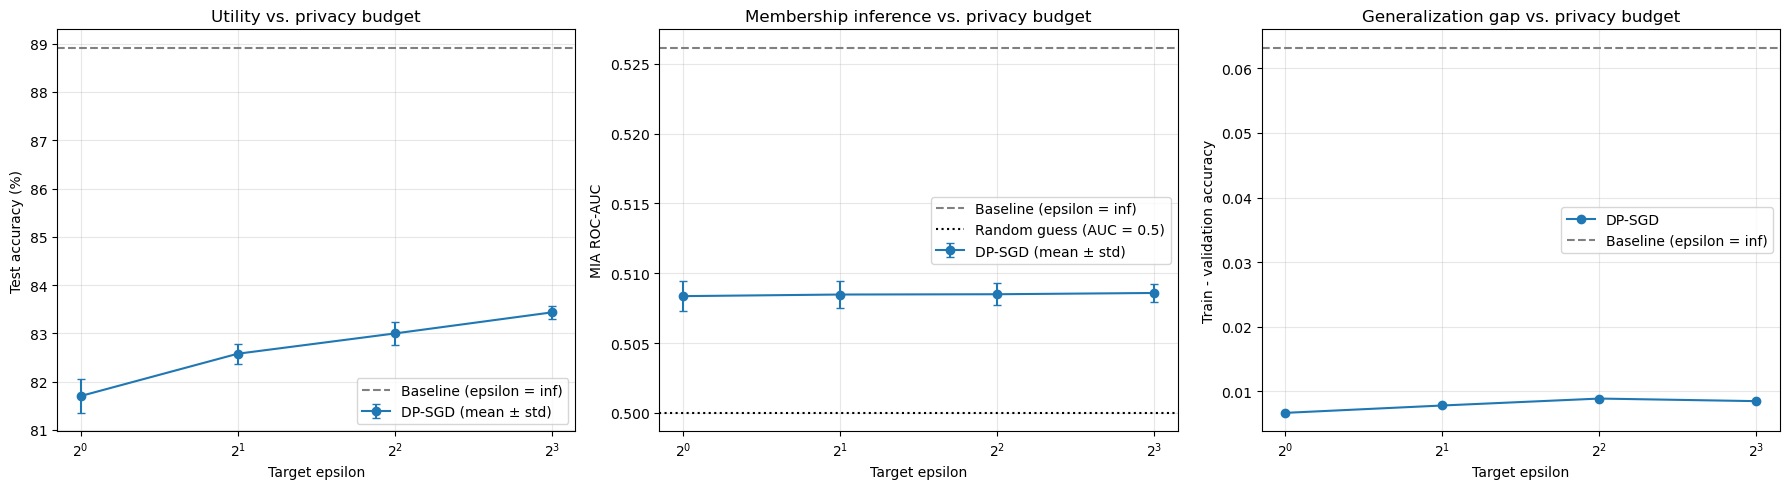

Figure saved to: C:\Users\HADIS\Documents\overfitting-privacy-neural-networks\results\figures\baseline_vs_dp_tradeoff.png


In [11]:
dp_summary = summary_df[summary_df["method"] == "DP-SGD"]
baseline_summary = summary_df[summary_df["method"] == "Baseline"].iloc[0]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].errorbar(
    dp_summary["target_epsilon"], dp_summary["test_accuracy_mean"] * 100,
    yerr=dp_summary["test_accuracy_std"] * 100, marker="o", capsize=3, label="DP-SGD (mean ± std)"
)
axes[0].axhline(baseline_summary["test_accuracy_mean"] * 100, linestyle="--", color="gray", label="Baseline (epsilon = inf)")
axes[0].set_xscale("log", base=2)
axes[0].set_xlabel("Target epsilon")
axes[0].set_ylabel("Test accuracy (%)")
axes[0].set_title("Utility vs. privacy budget")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].errorbar(
    dp_summary["target_epsilon"], dp_summary["mia_auc_mean"],
    yerr=dp_summary["mia_auc_std"], marker="o", capsize=3, label="DP-SGD (mean ± std)"
)
axes[1].axhline(baseline_summary["mia_auc_mean"], linestyle="--", color="gray", label="Baseline (epsilon = inf)")
axes[1].axhline(0.5, linestyle=":", color="black", label="Random guess (AUC = 0.5)")
axes[1].set_xscale("log", base=2)
axes[1].set_xlabel("Target epsilon")
axes[1].set_ylabel("MIA ROC-AUC")
axes[1].set_title("Membership inference vs. privacy budget")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].plot(dp_summary["target_epsilon"], dp_summary["accuracy_gap_mean"], marker="o", label="DP-SGD")
axes[2].axhline(baseline_summary["accuracy_gap_mean"], linestyle="--", color="gray", label="Baseline (epsilon = inf)")
axes[2].set_xscale("log", base=2)
axes[2].set_xlabel("Target epsilon")
axes[2].set_ylabel("Train - validation accuracy")
axes[2].set_title("Generalization gap vs. privacy budget")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()

tradeoff_path = FIGURES_DIR / "baseline_vs_dp_tradeoff.png"
plt.savefig(tradeoff_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", tradeoff_path)

## Relationship Between Overfitting and Membership Inference Risk

The baseline checkpoints from notebook 1 (epochs 5, 10, 20, 30; several training seeds) are used to relate the generalization gap to the attack performance. The DP-SGD runs are added to the same plot as additional points.

Checkpoints of one training run are snapshots of the same trajectory, and both the gap and the attack AUC tend to grow with the number of epochs. A correlation computed over these points is therefore a description of a shared trend, not an independent test of significance or of causation.

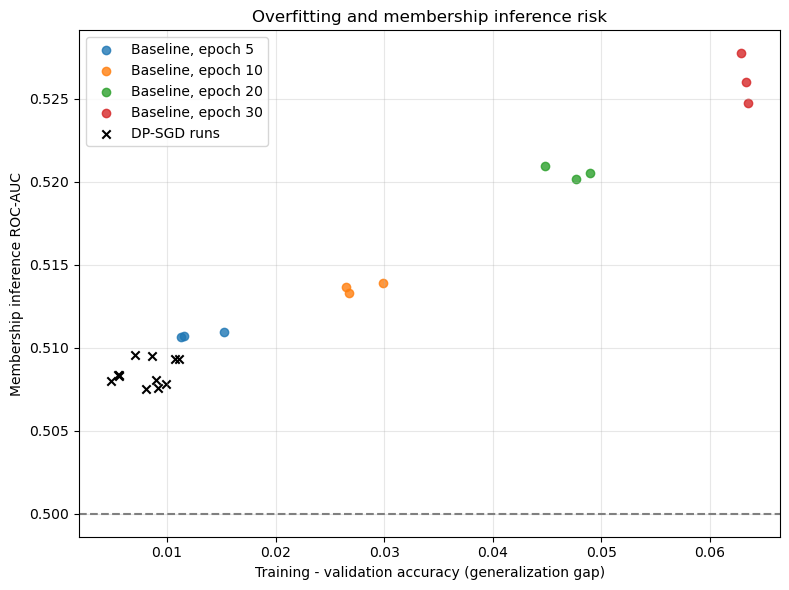

{
    "comparison": "Accuracy gap vs. MIA ROC-AUC (baseline checkpoints)",
    "pearson_correlation": 0.9843354012021984,
    "spearman_correlation": 0.9440559440559443,
    "number_of_points": 12,
    "number_of_seeds": 3,
    "epochs": [
        5,
        10,
        20,
        30
    ],
    "interpretation": "Descriptive association over checkpoints of a few training runs. The points are not independent (snapshots of the same runs); this does not establish causation or statistical significance."
}
Saved to: C:\Users\HADIS\Documents\overfitting-privacy-neural-networks\results\metrics\overfitting_mia_correlation.json


In [12]:
overfitting_mia = pd.read_csv(METRICS_DIR / "overfitting_vs_mia.csv")

pearson_r, _ = pearsonr(overfitting_mia["accuracy_gap"], overfitting_mia["mia_roc_auc"])
spearman_r, _ = spearmanr(overfitting_mia["accuracy_gap"], overfitting_mia["mia_roc_auc"])

fig, ax = plt.subplots(figsize=(8, 6))

for epoch, group in overfitting_mia.groupby("epoch"):
    ax.scatter(group["accuracy_gap"], group["mia_roc_auc"], label=f"Baseline, epoch {epoch}", alpha=0.8)

ax.scatter(
    dp_sweep_df["accuracy_gap"], dp_sweep_df["roc_auc"],
    marker="x", color="black", label="DP-SGD runs"
)
ax.axhline(0.5, linestyle="--", color="gray")
ax.set_xlabel("Training - validation accuracy (generalization gap)")
ax.set_ylabel("Membership inference ROC-AUC")
ax.set_title("Overfitting and membership inference risk")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()

overfitting_plot_path = FIGURES_DIR / "overfitting_vs_mia_auc.png"
plt.savefig(overfitting_plot_path, dpi=300, bbox_inches="tight")
plt.show()

correlation_summary = {
    "comparison": "Accuracy gap vs. MIA ROC-AUC (baseline checkpoints)",
    "pearson_correlation": float(pearson_r),
    "spearman_correlation": float(spearman_r),
    "number_of_points": int(len(overfitting_mia)),
    "number_of_seeds": int(overfitting_mia["seed"].nunique()),
    "epochs": sorted(overfitting_mia["epoch"].unique().tolist()),
    "interpretation": (
        "Descriptive association over checkpoints of a few training runs. The points are not "
        "independent (snapshots of the same runs); this does not establish causation or "
        "statistical significance."
    ),
}

correlation_path = METRICS_DIR / "overfitting_mia_correlation.json"
with open(correlation_path, "w", encoding="utf-8") as file:
    json.dump(correlation_summary, file, indent=4)

print(json.dumps(correlation_summary, indent=4))
print("Saved to:", correlation_path)

In [13]:
main_dp_mean = main_dp[["test_accuracy", "test_loss", "roc_auc", "auc_ci_low", "auc_ci_high",
                        "tpr_at_fpr_1pct", "accuracy_gap", "final_epsilon", "epsilon_wide_alphas"]].mean()
baseline_mean = baseline_df[["test_accuracy", "test_loss", "roc_auc", "auc_ci_low", "auc_ci_high",
                             "tpr_at_fpr_1pct", "accuracy_gap"]].mean()

final_summary = {
    "project": "The Impact of Overfitting on Privacy Risks in Neural Networks",
    "dataset": "Fashion-MNIST",
    "mia_member_source": "train",
    "mia_nonmember_source": "test",
    "train_seeds": TRAIN_SEEDS,
    "dp_seeds": DP_SEEDS,
    "epsilon_sweep": EPSILON_SWEEP,
    "main_epsilon": MAIN_EPSILON,
    "delta": TARGET_DELTA,
    "baseline_test_accuracy": float(baseline_mean["test_accuracy"]),
    "dp_test_accuracy": float(main_dp_mean["test_accuracy"]),
    "accuracy_drop_percentage_points": float((baseline_mean["test_accuracy"] - main_dp_mean["test_accuracy"]) * 100),
    "baseline_mia_auc": float(baseline_mean["roc_auc"]),
    "dp_mia_auc": float(main_dp_mean["roc_auc"]),
    "baseline_tpr_at_1pct_fpr": float(baseline_mean["tpr_at_fpr_1pct"]),
    "dp_tpr_at_1pct_fpr": float(main_dp_mean["tpr_at_fpr_1pct"]),
    "baseline_accuracy_gap": float(baseline_mean["accuracy_gap"]),
    "dp_accuracy_gap": float(main_dp_mean["accuracy_gap"]),
    "dp_final_epsilon": float(main_dp_mean["final_epsilon"]),
    "dp_epsilon_wide_alphas": float(main_dp_mean["epsilon_wide_alphas"]),
    "overfitting_mia_pearson": correlation_summary["pearson_correlation"],
    "overfitting_mia_spearman": correlation_summary["spearman_correlation"],
}

summary_json_path = METRICS_DIR / "final_results_summary.json"
with open(summary_json_path, "w", encoding="utf-8") as file:
    json.dump(final_summary, file, indent=4)

summary_text = f"""
### Final Experimental Summary (generated from the saved results)

**1. Predictive performance.** Mean over {len(TRAIN_SEEDS)} baseline seeds: test accuracy {baseline_mean['test_accuracy'] * 100:.2f}% (test loss {baseline_mean['test_loss']:.4f}).
DP-SGD with target epsilon {MAIN_EPSILON:g} (mean over {len(main_dp)} runs): test accuracy {main_dp_mean['test_accuracy'] * 100:.2f}% (test loss {main_dp_mean['test_loss']:.4f}),
a change of {(main_dp_mean['test_accuracy'] - baseline_mean['test_accuracy']) * 100:+.2f} percentage points. The full accuracy-vs-epsilon curve is in `baseline_vs_dp_tradeoff.png`.

**2. Membership inference.** Same attack, same members (training subset) and non-members (test set) for all models.
Baseline ROC-AUC {baseline_mean['roc_auc']:.4f} (mean bootstrap CI {baseline_mean['auc_ci_low']:.4f}-{baseline_mean['auc_ci_high']:.4f}), TPR at FPR<=1%: {baseline_mean['tpr_at_fpr_1pct']:.4f}.
DP-SGD (epsilon {MAIN_EPSILON:g}) ROC-AUC {main_dp_mean['roc_auc']:.4f} (mean bootstrap CI {main_dp_mean['auc_ci_low']:.4f}-{main_dp_mean['auc_ci_high']:.4f}), TPR at FPR<=1%: {main_dp_mean['tpr_at_fpr_1pct']:.4f}.
Values close to 0.5 indicate limited discrimination between members and non-members under this attack.

**3. Generalization gap.** Training-validation accuracy gap: baseline {baseline_mean['accuracy_gap']:.4f}, DP-SGD {main_dp_mean['accuracy_gap']:.4f}.

**4. Overfitting and membership inference.** Over the baseline checkpoints (epochs {correlation_summary['epochs']}, {correlation_summary['number_of_seeds']} seeds,
{correlation_summary['number_of_points']} points) the Pearson correlation between accuracy gap and AUC is {correlation_summary['pearson_correlation']:.4f}
(Spearman {correlation_summary['spearman_correlation']:.4f}). The points are snapshots of the same runs, so this is a descriptive association, not a significance test.

**5. Differential privacy parameters.** Target epsilon {MAIN_EPSILON:g}, delta {TARGET_DELTA:.0e}; reported final epsilon {main_dp_mean['final_epsilon']:.4f}
(recomputed with a wider RDP alpha grid: {main_dp_mean['epsilon_wide_alphas']:.4f}). The measured value is reported without rounding it down to the target.
"""

with open(METRICS_DIR / "final_results_summary.md", "w", encoding="utf-8") as file:
    file.write(summary_text)

display(Markdown(summary_text))
print("Saved to:", summary_json_path)


### Final Experimental Summary (generated from the saved results)

**1. Predictive performance.** Mean over 3 baseline seeds: test accuracy 88.92% (test loss 0.4000).
DP-SGD with target epsilon 8 (mean over 3 runs): test accuracy 83.43% (test loss 0.9001),
a change of -5.49 percentage points. The full accuracy-vs-epsilon curve is in `baseline_vs_dp_tradeoff.png`.

**2. Membership inference.** Same attack, same members (training subset) and non-members (test set) for all models.
Baseline ROC-AUC 0.5262 (mean bootstrap CI 0.5199-0.5326), TPR at FPR<=1%: 0.0101.
DP-SGD (epsilon 8) ROC-AUC 0.5086 (mean bootstrap CI 0.5037-0.5140), TPR at FPR<=1%: 0.0108.
Values close to 0.5 indicate limited discrimination between members and non-members under this attack.

**3. Generalization gap.** Training-validation accuracy gap: baseline 0.0632, DP-SGD 0.0085.

**4. Overfitting and membership inference.** Over the baseline checkpoints (epochs [5, 10, 20, 30], 3 seeds,
12 points) the Pearson correlation between accuracy gap and AUC is 0.9843
(Spearman 0.9441). The points are snapshots of the same runs, so this is a descriptive association, not a significance test.

**5. Differential privacy parameters.** Target epsilon 8, delta 1e-05; reported final epsilon 8.0071
(recomputed with a wider RDP alpha grid: 8.0071). The measured value is reported without rounding it down to the target.


Saved to: C:\Users\HADIS\Documents\overfitting-privacy-neural-networks\results\metrics\final_results_summary.json


In [14]:
limitations = [
    "Overfitting-MIA association: checkpoints of the same run are snapshots of one trajectory and are not independent; only a few training seeds are used and the data split is fixed.",
    "The association does not establish causality or statistical significance.",
    "Only one simple loss-based membership inference attack is evaluated; stronger attacks (e.g. shadow-model / LiRA-style) may find more leakage, so a low AUC is not a privacy proof.",
    "When the baseline attack AUC is itself close to 0.5, there is little room to show a privacy benefit of DP-SGD in this setting.",
    "DP-SGD hyperparameters (learning rate, clipping norm) were not tuned, so part of the utility loss may be due to untuned settings.",
    "Opacus warned that the optimal RDP order was the largest alpha of its default grid (the default epsilon may be loose); epsilon was therefore also recomputed with a wider alpha grid.",
    "The DP-SGD runs used non-secure randomness (secure mode off); they should not be presented as a production-grade privacy implementation.",
    "The reported final epsilon can be slightly above the target epsilon (calibration tolerance); the measured value is reported.",
    "One MLP architecture and one dataset are evaluated; results may not generalize.",
]

limitations_path = METRICS_DIR / "experimental_limitations.txt"

with open(limitations_path, "w", encoding="utf-8") as file:
    file.write("\n".join(f"- {item}" for item in limitations))

print("\n".join(f"- {item}" for item in limitations))
print(f"\nSaved to: {limitations_path}")

- Overfitting-MIA association: checkpoints of the same run are snapshots of one trajectory and are not independent; only a few training seeds are used and the data split is fixed.
- The association does not establish causality or statistical significance.
- Only one simple loss-based membership inference attack is evaluated; stronger attacks (e.g. shadow-model / LiRA-style) may find more leakage, so a low AUC is not a privacy proof.
- When the baseline attack AUC is itself close to 0.5, there is little room to show a privacy benefit of DP-SGD in this setting.
- DP-SGD hyperparameters (learning rate, clipping norm) were not tuned, so part of the utility loss may be due to untuned settings.
- Opacus warned that the optimal RDP order was the largest alpha of its default grid (the default epsilon may be loose); epsilon was therefore also recomputed with a wider alpha grid.
- The DP-SGD runs used non-secure randomness (secure mode off); they should not be presented as a production-grade pri

In [15]:
deliverables = [
    METRICS_DIR / "split_indices.json",
    METRICS_DIR / "baseline_vs_dp_comparison.csv",
    METRICS_DIR / "dp_sweep_results.csv",
    METRICS_DIR / "overfitting_vs_mia.csv",
    METRICS_DIR / "overfitting_mia_correlation.json",
    METRICS_DIR / "final_results_summary.json",
    METRICS_DIR / "final_results_summary.md",
    METRICS_DIR / "experimental_limitations.txt",
    FIGURES_DIR / "baseline_vs_dp_tradeoff.png",
    FIGURES_DIR / "overfitting_vs_mia_auc.png",
]

for path in deliverables:
    print(f"[{'OK' if path.exists() else 'MISSING'}] {path.name}")

[OK] split_indices.json
[OK] baseline_vs_dp_comparison.csv
[OK] dp_sweep_results.csv
[OK] overfitting_vs_mia.csv
[OK] overfitting_mia_correlation.json
[OK] final_results_summary.json
[OK] final_results_summary.md
[OK] experimental_limitations.txt
[OK] baseline_vs_dp_tradeoff.png
[OK] overfitting_vs_mia_auc.png
